In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit

In [ ]:
normal = pd.read_csv('Motor Normal.txt', names=['PWM', 'Force (N)']) # Brushless generico. 
normal

,PWM,Force (N)
0,1100,-0.027947
1,1100,-0.029734
2,1100,-0.028973
3,1100,-0.035551
4,1100,-0.124202
...,...,...
3472,2000,-5.397947
3473,2000,-5.416559
3474,2000,-5.462414
3475,2000,-5.393631


In [ ]:
good = pd.read_csv('Motor Bueno.txt', names=['PWM', 'Force (N)']) # Brushless obtenido de lanchita. 
good

,PWM,Force (N)
0,1100,-0.025570
1,1100,-0.028821
2,1100,-0.025856
3,1100,-0.031863
4,1100,0.003574
...,...,...
1215,1400,2.882072
1216,1400,2.979449
1217,1400,2.783878
1218,1400,2.829031


In [33]:
filtered_normal = pd.concat([normal.iloc[: 2240],  normal.iloc[2525:]])
filtered_normal['Force (N)'] = -1*filtered_normal['Force (N)']
filtered_normal

,PWM,Force (N)
0,1100,0.027947
1,1100,0.029734
2,1100,0.028973
3,1100,0.035551
4,1100,0.124202
...,...,...
3472,2000,5.397947
3473,2000,5.416559
3474,2000,5.462414
3475,2000,5.393631


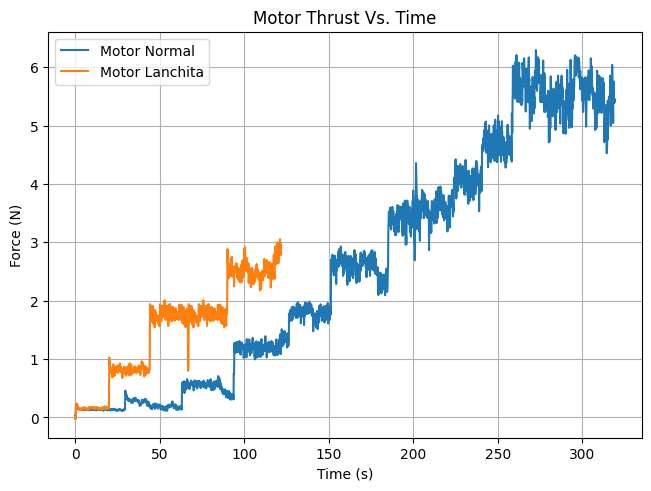

In [35]:
fig, ax = plt.subplots(layout='constrained')

ax.plot(np.arange(len(filtered_normal))/10, filtered_normal['Force (N)'], label='Motor Normal')
ax.plot(np.arange(len(good))/10, good['Force (N)'], label='Motor Lanchita')

ax.set(xlabel='Time (s)', ylabel='Force (N)', title='Motor Thrust Vs. Time')

ax.legend()
ax.grid()

plt.show()

In [37]:
def quadratic(x, a, b, c):
  return a*x**2 + b*x + c

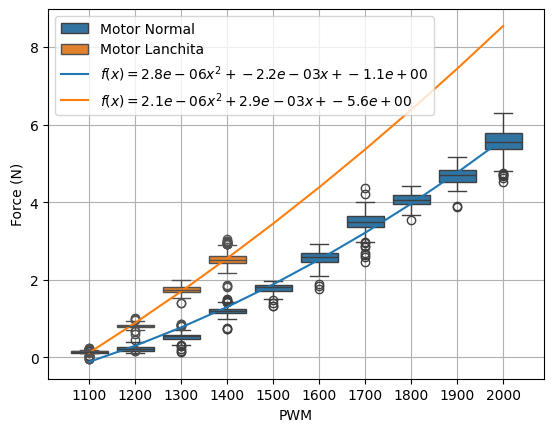

In [51]:
popt_normal, _ = curve_fit(quadratic, filtered_normal['PWM'], filtered_normal['Force (N)'])
popt_good, _ = curve_fit(quadratic, good['PWM'], good['Force (N)'])

sns.boxplot(data=filtered_normal, x='PWM', y='Force (N)', label='Motor Normal')
sns.boxplot(data=good, x='PWM', y='Force (N)', label='Motor Lanchita')

PWM_range = np.linspace(1100, 2000, 10)
plt.plot(quadratic(PWM_range, *popt_normal), label=f'$f(x) = {popt_normal[0]:.1e}x^2 + {popt_normal[1]:.1e}x + {popt_normal[2]:.1e}$')
plt.plot(quadratic(PWM_range, *popt_good), label=f'$f(x) = {popt_good[0]:.1e}x^2 + {popt_good[1]:.1e}x + {popt_good[2]:.1e}$')

plt.grid()
plt.legend()
plt.show()